In [7]:
import pandas as pd
from collections import defaultdict

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder, StandardScaler
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Multiclass Classification
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Miltilabel Classification
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import classification_report, hamming_loss, jaccard_score

# Time Series Analysis
import holidays




import pandas as pd
import numpy as np
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer

In [8]:
df = pd.read_csv("data/combined_h1_2018_2025_excl_nan.csv")
df.head()

# Re-arrange columns
cols = ["Datetime", "YearMonth", "Date", "Year", "Month", "Month_str", "Weekday", "Weekday_str", "Day", "Time",
        "Location",
        "NO2", "O3", "PM10",
        "Hr", "RainDur", "T", "WVv", "StrGlo",
        "meanVehicles"]

df = df[cols]
df.head()
# Select columns
cols_selected = ["Year", "Month", "Weekday", "Time", "Day",
                 "Location",
                 "NO2", "O3", "PM10",
                 "Hr", "RainDur", "T", "WVv", "StrGlo",
                 "meanVehicles"]

df_selected = df[cols_selected]

# Make sure the time features are numbers, not strings
df_ready = df_selected.copy()
df_ready["Time"] = pd.to_datetime(df_ready["Time"], format="%H:%M:%S").dt.hour.astype("int64")
df_ready["Month"] = df_selected["Month"].astype(int)
df_ready["Day"] = df_selected["Day"].astype(int)
df_ready["Weekday"] = df_selected["Weekday"].astype(int)

df_ready.head()

,Year,Month,Weekday,Time,Day,Location,NO2,O3,PM10,Hr,RainDur,T,WVv,StrGlo,meanVehicles
0,2018.0,12,6,23,31,Zch_Rosengartenstrasse,17.20,44.33,18.81,67.36,0.00,9.02,1.85,0.02,538.5
1,2018.0,12,6,23,31,Zch_Schimmelstrasse,9.33,49.89,16.57,64.18,0.00,9.60,0.70,0.02,340.0
2,2018.0,12,6,23,31,Zch_Stampfenbachstrasse,12.80,46.59,27.35,66.37,0.00,9.06,4.62,0.02,197.5
3,2018.0,1,0,0,1,Zch_Rosengartenstrasse,24.10,41.80,19.33,69.54,0.27,9.28,1.59,0.01,1029.0
4,2018.0,1,0,0,1,Zch_Schimmelstrasse,8.67,50.66,11.73,67.29,0.00,9.53,0.99,0.01,621.5


# Prepare transofrmer - to prepare data

In [9]:
from prepare_data_MLready import df_ready
df_ready.head()
from prepare_data_MLready import sin_transformer, cos_transformer, periodic_spline_transformer

# ADJUST: Prepare columns to be used
numeric_variables = ["Hr", "RainDur", "T", "WVv", "StrGlo", "meanVehicles", "NO2", "O3", "PM10"]

preprocess = ColumnTransformer(
    transformers=[
        ("Month_sin", sin_transformer(12), ["Month"]),
        ("Month_cos", cos_transformer(12), ["Month"]),
        ("Day_sin", sin_transformer(7), ["Day"]),
        ("Day_cos", cos_transformer(7), ["Day"]),
        ("Weekday_sin", sin_transformer(7), ["Weekday"]),
        ("Weekday_cos", cos_transformer(7), ["Weekday"]),
        ("Time_sin", sin_transformer(24), ["Time"]),
        ("Time_cos", cos_transformer(24), ["Time"]),
        ("Spline_month", periodic_spline_transformer(12, n_splines=5), ["Month"]),
        ("Spline_day", periodic_spline_transformer(7, n_splines=6), ["Day"]),
        ("Spline_weekday", periodic_spline_transformer(7, n_splines=6), ["Weekday"]),
        ("Spline_time", periodic_spline_transformer(24, n_splines=24), ["Time"]),
        #("encoded", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["Location"]),
        ("scaled", StandardScaler(), numeric_variables),
    ],
    remainder="passthrough"
).set_output(transform="pandas")

In [ ]:

# --- Split manually based on year (to make sure the whole year is always included)
y_df = df_ready[["Location"]].copy()  # DataFrame with a single column
X_df = df_ready.drop(columns=["Location"]).copy()

# Training datasets contain years 2018-2024
train_mask = X_df["Year"].between(2018, 2024)
test_mask  = X_df["Year"] == 2025

X_train = X_df.loc[train_mask].copy()
X_test  = X_df.loc[test_mask].copy()

# y_df split (still DataFrame), then convert to 1-D Series aligned to X
y_train_df = y_df.loc[train_mask].copy()
y_test_df  = y_df.loc[test_mask].copy()

# Convert to 1-D Series for scikit-learn
y_train = y_train_df.iloc[:, 0]  # or y_train_df.squeeze("columns")
y_test  = y_test_df.iloc[:, 0]

# Sanity check: indices must match X splits
assert (X_train.index.equals(y_train.index)), "Index mismatch between X_train and y_train"
assert (X_test.index.equals(y_test.index)), "Index mismatch between X_test and y_test"

# --- Fit/transform with your ColumnTransformer
preprocess.fit(X_train)
X_train_transformed = preprocess.transform(X_train)  # returns a DataFrame if set_output("pandas")
X_test_transformed  = preprocess.transform(X_test)

# Print transformed columns and head (as you requested)
print(X_train_transformed.columns.tolist())
print(X_train_transformed.head())

['Month_sin__Month', 'Month_cos__Month', 'Day_sin__Day', 'Day_cos__Day', 'Weekday_sin__Weekday', 'Weekday_cos__Weekday', 'Time_sin__Time', 'Time_cos__Time', 'Spline_month__Month_sp_0', 'Spline_month__Month_sp_1', 'Spline_month__Month_sp_2', 'Spline_month__Month_sp_3', 'Spline_month__Month_sp_4', 'Spline_day__Day_sp_0', 'Spline_day__Day_sp_1', 'Spline_day__Day_sp_2', 'Spline_day__Day_sp_3', 'Spline_day__Day_sp_4', 'Spline_day__Day_sp_5', 'Spline_weekday__Weekday_sp_0', 'Spline_weekday__Weekday_sp_1', 'Spline_weekday__Weekday_sp_2', 'Spline_weekday__Weekday_sp_3', 'Spline_weekday__Weekday_sp_4', 'Spline_weekday__Weekday_sp_5', 'Spline_time__Time_sp_0', 'Spline_time__Time_sp_1', 'Spline_time__Time_sp_2', 'Spline_time__Time_sp_3', 'Spline_time__Time_sp_4', 'Spline_time__Time_sp_5', 'Spline_time__Time_sp_6', 'Spline_time__Time_sp_7', 'Spline_time__Time_sp_8', 'Spline_time__Time_sp_9', 'Spline_time__Time_sp_10', 'Spline_time__Time_sp_11', 'Spline_time__Time_sp_12', 'Spline_time__Time_sp_13',

In [28]:
X_train_transformed.to_csv("data/Datasets_MLready_pred_Location/X_train_transformed_Loc.csv", index=False)
X_test_transformed.to_csv("data/Datasets_MLready_pred_Location/X_test_transformed_Loc.csv", index=False)
y_train.to_csv("data/Datasets_MLready_pred_Location/y_train_Loc.csv", index=False)
y_test.to_csv("data/Datasets_MLready_pred_Location/y_test_Loc.csv", index=False)

# Previous block from Jikta, does not work for me:

In [73]:
# Split manually based on year (to make sure the whole year is always included)
y_df = df_ready[["Location"]].copy()
#y = df_ready['Location'].map({'Zch_Rosengartenstrasse': 0, 'Zch_Schimmelstrasse': 1, 'Zch_Stampfenbachstrasse': 2})
#print(y)
X_df = df_ready.drop(columns=["Location"]).copy()

# Training datasets contain years 2018-2024
X_train = X_df[X_df["Year"].between(2018, 2024)].copy()
X_test = X_df[X_df["Year"] == 2025].copy()
# Testing datasets contain year 2025
y_train = y_df[X_df["Year"].between(2018, 2024)].copy()
y_test = y_df[X_df["Year"] == 2025].copy()

preprocess.fit(X_train)

X_train_transformed = preprocess.transform(X_train)
X_test_transformed = preprocess.transform(X_test)


print(X_train_transformed.columns.tolist())
print(X_train_transformed.head())

['Month_sin__Month', 'Month_cos__Month', 'Day_sin__Day', 'Day_cos__Day', 'Weekday_sin__Weekday', 'Weekday_cos__Weekday', 'Time_sin__Time', 'Time_cos__Time', 'Spline_month__Month_sp_0', 'Spline_month__Month_sp_1', 'Spline_month__Month_sp_2', 'Spline_month__Month_sp_3', 'Spline_month__Month_sp_4', 'Spline_day__Day_sp_0', 'Spline_day__Day_sp_1', 'Spline_day__Day_sp_2', 'Spline_day__Day_sp_3', 'Spline_day__Day_sp_4', 'Spline_day__Day_sp_5', 'Spline_weekday__Weekday_sp_0', 'Spline_weekday__Weekday_sp_1', 'Spline_weekday__Weekday_sp_2', 'Spline_weekday__Weekday_sp_3', 'Spline_weekday__Weekday_sp_4', 'Spline_weekday__Weekday_sp_5', 'Spline_time__Time_sp_0', 'Spline_time__Time_sp_1', 'Spline_time__Time_sp_2', 'Spline_time__Time_sp_3', 'Spline_time__Time_sp_4', 'Spline_time__Time_sp_5', 'Spline_time__Time_sp_6', 'Spline_time__Time_sp_7', 'Spline_time__Time_sp_8', 'Spline_time__Time_sp_9', 'Spline_time__Time_sp_10', 'Spline_time__Time_sp_11', 'Spline_time__Time_sp_12', 'Spline_time__Time_sp_13',

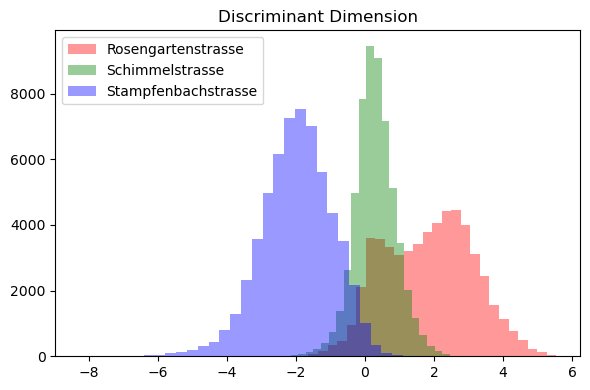

Explained variance ratio: [0.92519727]


In [ ]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

# Map station names -> class codes (adjust names if needed)
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
y_train_codes = y_train.map(loc_to_code).astype("int64")

# Select the scaled variables (except time related ones))
feature_columns_names = [
    'scaled__Hr', 'scaled__RainDur', 'scaled__T', 'scaled__WVv',
    'scaled__StrGlo', 'scaled__meanVehicles', 'scaled__NO2',
    'scaled__O3', 'scaled__PM10'
]

# Select all:
feature_columns_names = X_train_transformed.columns.tolist()

# Fit LDA, project to 1D
lda = LDA(n_components=1)
X_train_lda = lda.fit_transform(X_train_transformed[feature_columns_names], y_train_codes)

# Plot 3 histograms by class (ensure y is a 1-D array)
y_arr = np.asarray(y_train_codes)
kwargs = dict(histtype='stepfilled', alpha=0.4, density=False, bins=30)

plt.figure(figsize=(6,4))
plt.hist(X_train_lda[y_arr == 0].ravel(), **kwargs, label="Rosengartenstrasse", color='red')
plt.hist(X_train_lda[y_arr == 1].ravel(), **kwargs, label="Schimmelstrasse", color='green')
plt.hist(X_train_lda[y_arr == 2].ravel(), **kwargs, label="Stampfenbachstrasse", color='blue')
plt.legend()
plt.title("Discriminant Dimension")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", getattr(lda, "explained_variance_ratio_", None))

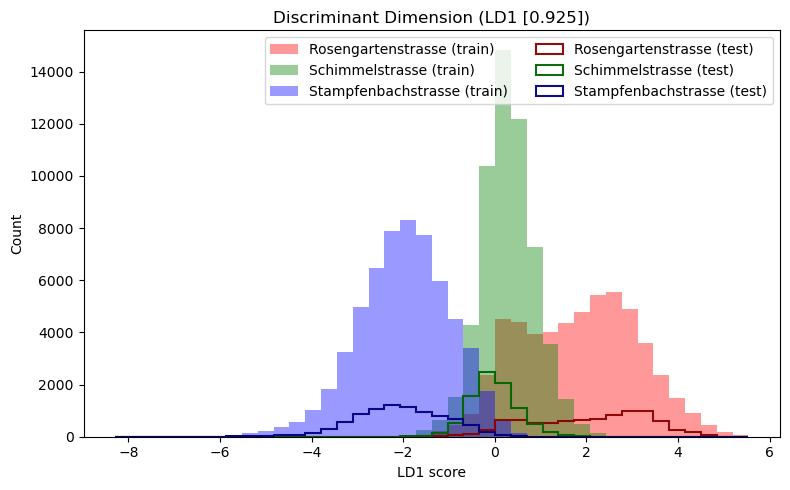

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer

# Ensure 1-D label Series (if you still have DataFrames)
if hasattr(y_train, "ndim") and y_train.ndim == 2:
    y_train = y_train.iloc[:, 0]
if hasattr(y_test, "ndim") and y_test.ndim == 2:
    y_test = y_test.iloc[:, 0]

# Map station names -> class codes
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
labels_for_legend = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']
train_colors = ['red', 'green', 'blue']   # filled
test_colors  = ['darkred', 'darkgreen', 'navy']  # outlined (contrast)

y_train_codes = y_train.map(loc_to_code).astype("int64").values
y_test_codes  = y_test.map(loc_to_code).astype("int64").values

# Use all transformed features (or replace with your scaled__ list)
feature_columns_names = X_train_transformed.columns.tolist()

# Impute NaNs for LDA
from sklearn.impute import SimpleImputer
imp = SimpleImputer(strategy="median")
X_train_imp = imp.fit_transform(X_train_transformed[feature_columns_names])
X_test_imp  = imp.transform(X_test_transformed[feature_columns_names])

# Fit LDA (1D) on train; project both train & test
lda = LDA(n_components=1, solver="svd")  # Standard default solver (also good for collinearity issues); if collinearity issues appear, use solver='lsqr', shrinkage='auto'  
X_train_lda = lda.fit_transform(X_train_imp, y_train_codes)
X_test_lda  = lda.transform(X_test_imp)

# Explained variance for title
evr = getattr(lda, "explained_variance_ratio_", None)
title = "Discriminant Dimension"
if evr is not None and len(evr) >= 1:
    title += f" (LD1 [{evr[0]:.3f}])"

# --- Plot TRAIN (filled) + TEST (outlined) histograms per class ---
plt.figure(figsize=(8, 5))

bins = 40  # consistent bins for train and test
alpha_train = 0.40
alpha_test  = 0.95

# Compute a common bin range across both train and test for fair comparison
low  = min(X_train_lda.min(), X_test_lda.min())
high = max(X_train_lda.max(), X_test_lda.max())
bin_edges = np.linspace(low, high, bins + 1)

# TRAIN: filled histograms
for cls, color, label in zip([0, 1, 2], train_colors, labels_for_legend):
    mask = (y_train_codes == cls)
    if mask.any():
        plt.hist(
            X_train_lda[mask, 0].ravel(),
            bins=bin_edges,
            histtype='stepfilled',
            alpha=alpha_train,
            density=False,  # set True if you prefer probability density
            label=f"{label} (train)",
            color=color
        )

# TEST: outlined histograms overlay (stepped, no fill)
for cls, color, label in zip([0, 1, 2], test_colors, labels_for_legend):
    mask = (y_test_codes == cls)
    if mask.any():
        plt.hist(
            X_test_lda[mask, 0].ravel(),
            bins=bin_edges,
            histtype='step',
            linewidth=1.5,
            alpha=alpha_test,
            density=False,
            label=f"{label} (test)",
            color=color
        )

plt.legend(ncol=2)
plt.title(title)
plt.xlabel("LD1 score")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer

# Ensure 1-D label Series
if hasattr(y_train, "ndim") and y_train.ndim == 2:
    y_train = y_train.iloc[:, 0]
if hasattr(y_test, "ndim") and y_test.ndim == 2:
    y_test = y_test.iloc[:, 0]

# Map station names -> class codes
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
labels_for_legend = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']
colors = ['g', 'r', 'b']  # green, red, blue

y_train_codes = y_train.map(loc_to_code).astype("int64")
y_test_codes  = y_test.map(loc_to_code).astype("int64")

# Choose feature set (here: all transformed columns; replace with your scaled__... list if desired)
feature_columns_names = X_train_transformed.columns.tolist()

# Impute and fit LDA to 2 components
imp = SimpleImputer(strategy="median")
X_train_imp = imp.fit_transform(X_train_transformed[feature_columns_names])
X_test_imp  = imp.transform(X_test_transformed[feature_columns_names])

lda = LDA(n_components=1, solver="svd")  # Standard default solver (also good for collinearity issues); if collinearity issues appear, use solver='lsqr', shrinkage='auto'
X_train_lda = lda.fit_transform(X_train_imp, y_train_codes.values)
X_test_lda  = lda.transform(X_test_imp)





# Plot 3 histograms by class (ensure y is a 1-D array)
y_arr = np.asarray(y_train_codes)
kwargs = dict(histtype='stepfilled', alpha=0.4, density=False, bins=30)

plt.figure(figsize=(6,4))
plt.hist(X_train_lda[y_arr == 0].ravel(), **kwargs, label="Rosengartenstrasse", color='red')
plt.hist(X_train_lda[y_arr == 1].ravel(), **kwargs, label="Schimmelstrasse", color='green')
plt.hist(X_train_lda[y_arr == 2].ravel(), **kwargs, label="Stampfenbachstrasse", color='blue')
plt.legend()
plt.title("Discriminant Dimension")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", getattr(lda, "explained_variance_ratio_", None))






# Axis labels with explained variance
evr = getattr(lda, "explained_variance_ratio_", None)
if evr is not None and len(evr) >= 2:
    xlab = f"LD1 [{evr[0]:.3f}]"
    ylab = f"LD2 [{evr[1]:.3f}]"
else:
    xlab, ylab = "LD1", "LD2"

# --- Plot in your exact style: train filled, test hollow ---
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(1,1,1) 
ax.set_xlabel(xlab, fontsize=15)
ax.set_ylabel(ylab, fontsize=15)
ax.set_title('LDA on Stations', fontsize=20)

# Train (filled)
for cls, color, label in zip([0, 1, 2], colors, labels_for_legend):
    indicesToKeep = (y_train_codes.values == cls)
    if indicesToKeep.any():
        ax.scatter(
            X_train_lda[indicesToKeep, 0],
            X_train_lda[indicesToKeep, 1],
            c=color, s=0.4, alpha=0.4, label=label
        )
colors = ['lightgreen', 'lightcoral', 'lightblue']
# Test (hollow)
for cls, color, label in zip([0, 1, 2], colors, labels_for_legend):
    indicesToKeepTest = (y_test_codes.values == cls)
    if indicesToKeepTest.any():
        ax.scatter(
            X_test_lda[indicesToKeepTest, 0],
            X_test_lda[indicesToKeepTest, 1],
            s=0.5, alpha=0.6,
            facecolors='none', edgecolors=color, linewidths=1.2,
            label=f"{label} (test)"
        )

# Legend lists each label once; deduplicate entries
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys())

ax.grid()
plt.tight_layout()
plt.show()

print("Explained variance ratio (LD1, LD2):", evr)

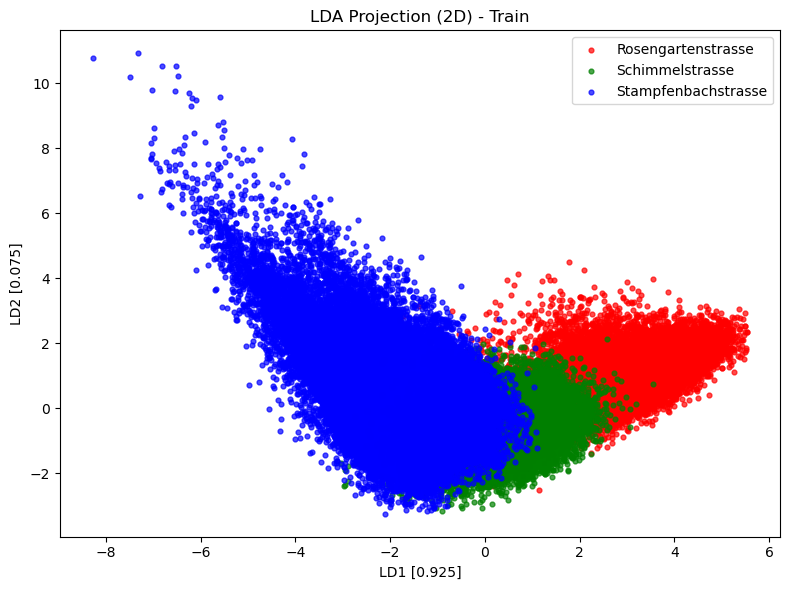

Explained variance ratio: [0.92519727 0.07480273]


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer

# Map station names -> class codes (adjust if needed)
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
y_train_codes = y_train.map(loc_to_code).astype("int64")  # 1-D integer labels

# Select the scaled variables (except time related ones))
feature_columns_names = [
    'scaled__Hr', 'scaled__RainDur', 'scaled__T', 'scaled__WVv',
    'scaled__StrGlo', 'scaled__meanVehicles', 'scaled__NO2',
    'scaled__O3', 'scaled__PM10'
]

# Use all transformed features (your current setting)
feature_columns_names = X_train_transformed.columns.tolist()

# Fit LDA to 2 components (max components = n_classes - 1 = 2)
lda = LDA(n_components=2, solver="svd")  # Standard default solver (also good for collinearity issues); if collinearity issues appear, use solver='lsqr', shrinkage='auto'
X_train_lda = lda.fit_transform(X_train_transformed[feature_columns_names], y_train_codes)

# Axis labels with explained variance (if available)
evr = getattr(lda, "explained_variance_ratio_", None)
xlab = f"LD1 [{evr[0]:.3f}]" if evr is not None and len(evr) >= 1 else "LD1"
ylab = f"LD2 [{evr[1]:.3f}]" if evr is not None and len(evr) >= 2 else "LD2"

# 2D scatter
colors = ['red', 'green', 'blue']
labels = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']
y_arr = np.asarray(y_train_codes)

plt.figure(figsize=(8, 6))
for cls, color, label in zip([0, 1, 2], colors, labels):
    mask = (y_arr == cls)
    plt.scatter(X_train_lda[mask, 0], X_train_lda[mask, 1],
                s=12, alpha=0.7, color=color, label=label)

plt.xlabel(xlab)
plt.ylabel(ylab)
plt.title("LDA Projection (2D) - Train")
plt.legend()
plt.tight_layout()
plt.show()

print("Explained variance ratio:", evr)


In [13]:

import numpy as np
import pandas as pd

# Make sure y_train is 1-D; you said you already did that
print("Unique classes in y_train:", pd.Series(y_train).unique())
print("Class counts:\n", pd.Series(y_train).value_counts())

# How many class codes present in the TRAIN split?
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
y_train_codes = y_train.map(loc_to_code).astype("int64")
classes_present = np.unique(y_train_codes.values)
print("Class codes present in train:", classes_present, " -> n_classes:", classes_present.size)

# Check LDA output shape you obtained:
print("X_train_lda shape:", X_train_lda.shape)  # probably (n, 1)


Unique classes in y_train: ['Zch_Rosengartenstrasse' 'Zch_Schimmelstrasse' 'Zch_Stampfenbachstrasse']
Class counts:
 Location
Zch_Stampfenbachstrasse    59329
Zch_Schimmelstrasse        57149
Zch_Rosengartenstrasse     54920
Name: count, dtype: int64
Class codes present in train: [0 1 2]  -> n_classes: 3
X_train_lda shape: (171398, 2)


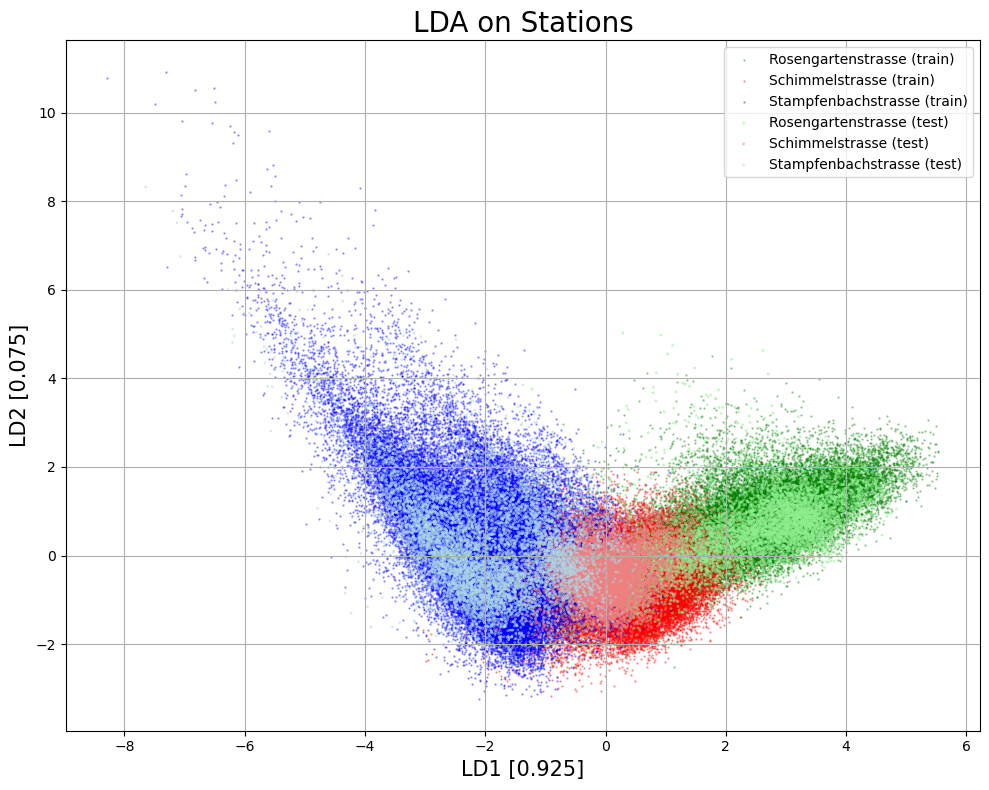

Explained variance ratio (LD1, LD2): [0.92519727 0.07480273]


In [32]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.impute import SimpleImputer

# Ensure 1-D label Series
if hasattr(y_train, "ndim") and y_train.ndim == 2:
    y_train = y_train.iloc[:, 0]
if hasattr(y_test, "ndim") and y_test.ndim == 2:
    y_test = y_test.iloc[:, 0]

# Map station names -> class codes
loc_to_code = {
    'Zch_Rosengartenstrasse': 0,
    'Zch_Schimmelstrasse': 1,
    'Zch_Stampfenbachstrasse': 2
}
labels_for_legend = ['Rosengartenstrasse', 'Schimmelstrasse', 'Stampfenbachstrasse']
colors = ['g', 'r', 'b']  # green, red, blue

y_train_codes = y_train.map(loc_to_code).astype("int64")
y_test_codes  = y_test.map(loc_to_code).astype("int64")

# Choose feature set (here: all transformed columns; replace with your scaled__... list if desired)
feature_columns_names = X_train_transformed.columns.tolist()

# Impute and fit LDA to 2 components
imp = SimpleImputer(strategy="median")
X_train_imp = imp.fit_transform(X_train_transformed[feature_columns_names])
X_test_imp  = imp.transform(X_test_transformed[feature_columns_names])

lda = LDA(n_components=2, solver="svd")  # Standard default solver (also good for collinearity issues); if collinearity issues appear, use solver='lsqr', shrinkage='auto'
X_train_lda = lda.fit_transform(X_train_imp, y_train_codes.values)
X_test_lda  = lda.transform(X_test_imp)

# Axis labels with explained variance
evr = getattr(lda, "explained_variance_ratio_", None)
if evr is not None and len(evr) >= 2:
    xlab = f"LD1 [{evr[0]:.3f}]"
    ylab = f"LD2 [{evr[1]:.3f}]"
else:
    xlab, ylab = "LD1", "LD2"

# --- Plot in your exact style: train filled, test hollow ---
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(1,1,1) 
ax.set_xlabel(xlab, fontsize=15)
ax.set_ylabel(ylab, fontsize=15)
ax.set_title('LDA on Stations', fontsize=20)

# Train (filled)
for cls, color, label in zip([0, 1, 2], colors, labels_for_legend):
    indicesToKeep = (y_train_codes.values == cls)
    if indicesToKeep.any():
        ax.scatter(
            X_train_lda[indicesToKeep, 0],
            X_train_lda[indicesToKeep, 1],
            c=color, s=0.4, alpha=0.4, label=f"{label} (train)"
        )
colors = ['lightgreen', 'lightcoral', 'lightblue']
# Test (hollow)
for cls, color, label in zip([0, 1, 2], colors, labels_for_legend):
    indicesToKeepTest = (y_test_codes.values == cls)
    if indicesToKeepTest.any():
        ax.scatter(
            X_test_lda[indicesToKeepTest, 0],
            X_test_lda[indicesToKeepTest, 1],
            s=0.5, alpha=0.6,
            facecolors='none', edgecolors=color, linewidths=1.2,
            label=f"{label} (test)"
        )

# Legend lists each label once; deduplicate entries
handles, labels = ax.get_legend_handles_labels()
uniq = dict(zip(labels, handles))
ax.legend(uniq.values(), uniq.keys())

ax.grid()
plt.tight_layout()
plt.show()

print("Explained variance ratio (LD1, LD2):", evr)


In [41]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

def plot_lda_arrow_loadings(lda, feature_names, scale=2.0, component_x=0, component_y=1, top_k=None):
    """
    Arrow plot of LDA loadings (scalings_) analogous to PCA loading arrow plot.
    
    Parameters
    ----------
    lda : fitted LinearDiscriminantAnalysis with solver='svd'
        Must expose `scalings_` and `explained_variance_ratio_`.
    feature_names : list[str]
        Names of the features in the order used to fit the model.
    scale : float
        Purely aesthetic scaling of arrow lengths for visibility.
    component_x, component_y : int
        Which discriminant components to plot on the x/y axes (0-based).
        With K classes, you can plot at most components 0..K-2.
    top_k : int or None
        If set, plot only the top-k features by 2D loading norm to reduce clutter.
    """
    if not hasattr(lda, "scalings_"):
        raise ValueError("LDA.scalings_ not available. Use solver='svd' (the default).")

    loadings = np.asarray(lda.scalings_)  # shape: (n_features, n_components)
    n_features, n_components = loadings.shape
    if max(component_x, component_y) >= n_components:
        raise ValueError(f"Requested components exceed available ({n_components}).")

    # 2D loadings for the selected components
    L2D = loadings[:, [component_x, component_y]]  # (n_features, 2)

    # Optional: select top-k by 2D norm (makes labels readable)
    if top_k is not None and top_k < n_features:
        norms = np.linalg.norm(L2D, axis=1)
        idx = np.argsort(norms)[::-1][:top_k]
        L2D = L2D[idx]
        names = [feature_names[i] for i in idx]
    else:
        names = feature_names

    # Scale for display (aesthetic only)
    L2D_scaled = L2D * scale

    # Plot
    plt.figure(figsize=(10, 30))
    plt.axhline(0, color='gray', lw=0.8)
    plt.axvline(0, color='gray', lw=0.8)

    for (x, y), feat in zip(L2D_scaled, names):
        plt.arrow(0, 0, x, y,
                  color='black', alpha=0.85, width=0.004, head_width=0.07,
                  length_includes_head=True)
        plt.text(x * 1.08, y * 1.08, feat, fontsize=10, ha='center', va='center')

    # Axis labels with EVR (if available)
    evr = getattr(lda, "explained_variance_ratio_", None)
    xlabel = f'LD{component_x+1}' + (f' (EVR: {evr[component_x]:.2%})' if evr is not None else '')
    ylabel = f'LD{component_y+1}' + (f' (EVR: {evr[component_y]:.2%})' if evr is not None else '')

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title('LDA Loadings (Arrow Plot)')
    plt.gca().set_aspect('equal', adjustable='box')
    plt.grid(alpha=0.15)
    plt.tight_layout()
    plt.show()

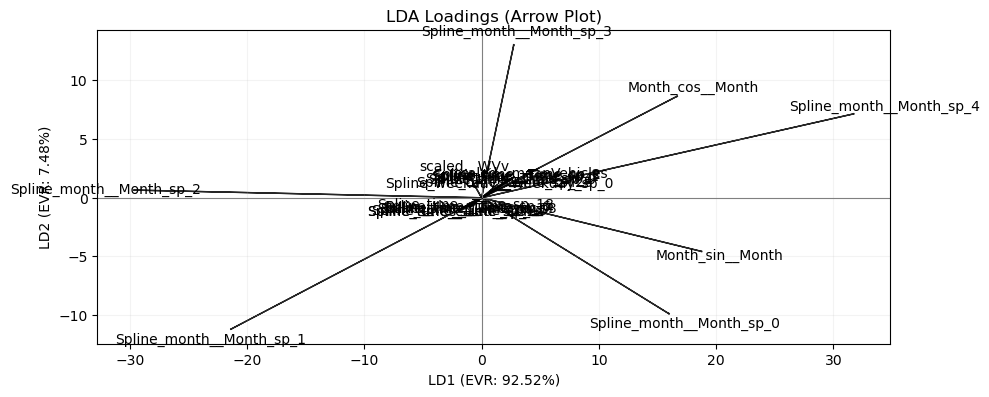

In [42]:
# After you've fitted:
# lda.fit(X_train_transformed[feature_columns_names], y_train_codes)

plot_lda_arrow_loadings(
    lda,
    feature_names=feature_columns_names,
    scale=2.0,
    component_x=0,          # LD1
    component_y=1,          # LD2 (requires >= 3 classes)
    top_k=25                # optional: show top 25 arrows
)